# Pushback Failure Case Plots

This notebook creates the failure-case trajectory plots used in the paper.

Each plot shows the manually labelled pushback segment together with one or both rule-based baseline methods.

In [1]:
from __future__ import annotations

import ast
import json
import re
from pathlib import Path
from typing import Optional

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cartes.crs import Mercator
from matplotlib.lines import Line2D
from traffic.core import Flight, Traffic
from traffic.data import airports


# =============================================================================
# Project paths
# =============================================================================

PROJECT_ROOT = Path.home() / "Projects" / "OSN_pushback_detection"

TEST_DATA_ROOT = (
    PROJECT_ROOT
    / "data"
    / "test"
    / "01_fetched"
)

GROUND_TRUTH_ROOT = (
    PROJECT_ROOT
    / "data"
    / "test"
    / "02_labeled"
)

RESULTS_ROOT = (
    PROJECT_ROOT
    / "results"
    / "plots"
)

RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# =============================================================================
# Plot style
# =============================================================================

TRAJECTORY_COLOR = "#7A4E8A"

GROUND_TRUTH_COLOR = "#0072B2"

PARKING_POSITION_COLOR = "#009E73"

PARKING_AREA_COLOR = "#E69F00"

TRAJECTORY_LINEWIDTH = 2.2
SEGMENT_LINEWIDTH = 4.0


## Plot function

`create_pushback_comparison_plot()` handles the complete workflow for one failure-case figure.

For each plot, select whether `parking_position`, `parking_area`, or both methods should be shown.

In [2]:
# =============================================================================
# Helper functions
# =============================================================================

def _metres_to_latitude_degrees(
    distance_m: float,
) -> float:
    """Convert a north/south distance in metres to latitude degrees."""

    return distance_m / 111_320.0


def _metres_to_longitude_degrees(
    distance_m: float,
    latitude: float,
) -> float:
    """Convert an east/west distance in metres to longitude degrees."""

    longitude_scale = np.cos(
        np.deg2rad(latitude)
    )

    if abs(longitude_scale) < 1e-8:
        raise ValueError(
            "Longitude conversion is undefined this close to the poles."
        )

    return distance_m / (
        111_320.0 * longitude_scale
    )


def _determine_plot_centre(
    centre_source_data: pd.DataFrame,
    *,
    center_point: Optional[int],
    center_coordinates: Optional[
        tuple[float, float]
    ],
    center_offset_east_m: float,
    center_offset_north_m: float,
) -> tuple[float, float]:
    """
    Determine the exact centre of the plot.

    center_point uses one-based numbering:
        center_point=1   -> first point
        center_point=300 -> 300th point
    """

    if (
        center_point is not None
        and center_coordinates is not None
    ):
        raise ValueError(
            "Use either center_point or center_coordinates, not both."
        )

    if center_coordinates is not None:
        if len(center_coordinates) != 2:
            raise ValueError(
                "center_coordinates must be given as "
                "(longitude, latitude)."
            )

        center_longitude = float(
            center_coordinates[0]
        )
        center_latitude = float(
            center_coordinates[1]
        )

    else:
        number_of_points = len(
            centre_source_data
        )

        if number_of_points == 0:
            raise ValueError(
                "The trajectory does not contain any valid coordinates."
            )

        if center_point is None:
            center_point = (
                number_of_points + 1
            ) // 2

        if not 1 <= center_point <= number_of_points:
            raise ValueError(
                f"center_point={center_point} is invalid. "
                f"The trajectory contains {number_of_points} valid points."
            )

        row = centre_source_data.iloc[
            center_point - 1
        ]

        center_longitude = float(
            row["longitude"]
        )
        center_latitude = float(
            row["latitude"]
        )

    center_latitude += (
        _metres_to_latitude_degrees(
            center_offset_north_m
        )
    )

    center_longitude += (
        _metres_to_longitude_degrees(
            center_offset_east_m,
            center_latitude,
        )
    )

    return (
        center_longitude,
        center_latitude,
    )


def _clean_flight(
    flight: Flight,
) -> Flight:
    """Remove invalid and consecutive duplicate coordinates for plotting."""

    data = (
        flight.data
        .dropna(
            subset=[
                "longitude",
                "latitude",
            ]
        )
        .copy()
    )

    if "timestamp" in data.columns:
        data = data.sort_values(
            "timestamp"
        )

    data = data.loc[
        ~(
            data["longitude"].eq(
                data["longitude"].shift()
            )
            & data["latitude"].eq(
                data["latitude"].shift()
            )
        )
    ].reset_index(drop=True)

    return Flight(data)


def _parse_structured_value(
    value,
):
    """Parse JSON/Python-literal values while preserving native objects."""

    if value is None:
        return None

    if (
        isinstance(value, float)
        and np.isnan(value)
    ):
        return None

    if not isinstance(value, str):
        return value

    value = value.strip()

    if not value:
        return None

    try:
        return json.loads(value)
    except (json.JSONDecodeError, TypeError):
        try:
            return ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return value


def _read_annotations(
    annotation_directory: Path,
) -> pd.DataFrame:
    """Load annotations.csv or annotations.json from one labelled dataset."""

    csv_path = (
        annotation_directory
        / "annotations.csv"
    )

    json_path = (
        annotation_directory
        / "annotations.json"
    )

    if csv_path.exists():
        return pd.read_csv(
            csv_path
        )

    if json_path.exists():
        content = json.loads(
            json_path.read_text(
                encoding="utf-8"
            )
        )

        if isinstance(content, list):
            return pd.DataFrame(
                content
            )

        if isinstance(content, dict):
            for key in [
                "annotations",
                "labels",
                "records",
                "data",
            ]:
                if isinstance(
                    content.get(key),
                    list,
                ):
                    return pd.DataFrame(
                        content[key]
                    )

    raise FileNotFoundError(
        "No annotations.csv or annotations.json found in "
        f"{annotation_directory}"
    )


def _find_annotation_row(
    annotations: pd.DataFrame,
    flight_identifier: str,
) -> pd.Series:
    """Resolve the requested flight in the manually labelled annotations."""

    if "flight_id" not in annotations.columns:
        raise ValueError(
            "The annotations do not contain a 'flight_id' column."
        )

    flight_identifier = str(
        flight_identifier
    )

    ids = (
        annotations["flight_id"]
        .astype(str)
    )

    exact = annotations.loc[
        ids.eq(flight_identifier)
    ]

    if len(exact) == 1:
        return exact.iloc[0]

    prefixed = annotations.loc[
        ids.str.startswith(
            f"{flight_identifier}_"
        )
    ]

    if len(prefixed) == 1:
        return prefixed.iloc[0]

    if len(prefixed) > 1:
        raise ValueError(
            f"Multiple labelled flights match {flight_identifier!r}: "
            f"{prefixed['flight_id'].astype(str).tolist()}"
        )

    raise ValueError(
        f"No labelled flight matching {flight_identifier!r} was found."
    )


def _segment_interval(
    segment,
) -> tuple[pd.Timestamp, pd.Timestamp] | None:
    """Extract a timestamp interval from one labelled segment."""

    segment = _parse_structured_value(
        segment
    )

    if isinstance(segment, dict):
        start = None
        end = None

        for key in [
            "start_ts",
            "start",
            "segment_start",
            "pushback_start",
            "begin",
            "from",
        ]:
            if key in segment:
                start = segment[key]
                break

        for key in [
            "end_ts",
            "end",
            "segment_end",
            "pushback_end",
            "stop",
            "to",
        ]:
            if key in segment:
                end = segment[key]
                break

    elif (
        isinstance(segment, (list, tuple))
        and len(segment) >= 2
    ):
        start = segment[0]
        end = segment[1]

    else:
        return None

    start = pd.to_datetime(
        start,
        errors="coerce",
        utc=True,
    )

    end = pd.to_datetime(
        end,
        errors="coerce",
        utc=True,
    )

    if (
        pd.isna(start)
        or pd.isna(end)
    ):
        return None

    return (
        min(start, end),
        max(start, end),
    )


def _load_ground_truth_segment(
    flight: Flight,
    annotation_row: pd.Series,
) -> Optional[Flight]:
    """
    Create the manually labelled pushback segment as a Flight object.

    Returns None if the flight has no manually labelled pushback segment.
    """

    segment_column = next(
        (
            column
            for column in [
                "pushback_segments",
                "pb_segments",
            ]
            if column in annotation_row.index
        ),
        None,
    )

    segments = []

    # -------------------------------------------------------------------------
    # Read pushback segment column
    # -------------------------------------------------------------------------

    if segment_column is not None:

        parsed = _parse_structured_value(
            annotation_row[segment_column]
        )

        if isinstance(parsed, dict):

            for key in [
                "pushback_segments",
                "pb_segments",
                "segments",
            ]:
                if isinstance(
                    parsed.get(key),
                    (list, tuple),
                ):
                    parsed = parsed[key]
                    break

            else:
                parsed = [parsed]

        if isinstance(
            parsed,
            (list, tuple),
        ):
            segments = list(
                parsed
            )

    # -------------------------------------------------------------------------
    # Fallback for tables containing direct start/end columns
    # -------------------------------------------------------------------------

    if not segments:

        direct_segment = {}

        for source, target in [
            ("segment_start", "start"),
            ("start_ts", "start"),
            ("pushback_start", "start"),
            ("segment_end", "end"),
            ("end_ts", "end"),
            ("pushback_end", "end"),
        ]:

            if (
                source in annotation_row.index
                and pd.notna(
                    annotation_row[source]
                )
            ):
                direct_segment[target] = (
                    annotation_row[source]
                )

        if (
            "start" in direct_segment
            and "end" in direct_segment
        ):
            segments = [
                direct_segment
            ]

    # -------------------------------------------------------------------------
    # No manually labelled pushback
    # -------------------------------------------------------------------------

    if not segments:
        return None

    # -------------------------------------------------------------------------
    # Extract timestamp intervals
    # -------------------------------------------------------------------------

    intervals = [
        interval
        for interval in (
            _segment_interval(
                segment
            )
            for segment in segments
        )
        if interval is not None
    ]

    flight_data = (
        flight.data.copy()
    )

    if "timestamp" in flight_data.columns:

        flight_data["timestamp"] = (
            pd.to_datetime(
                flight_data["timestamp"],
                errors="coerce",
                utc=True,
            )
        )

    # -------------------------------------------------------------------------
    # Preferred: timestamp-based ground truth
    # -------------------------------------------------------------------------

    if intervals:

        start = min(
            interval[0]
            for interval in intervals
        )

        end = max(
            interval[1]
            for interval in intervals
        )

        gt_data = flight_data.loc[
            flight_data["timestamp"].between(
                start,
                end,
            )
        ].copy()

        if len(gt_data) >= 2:

            return Flight(
                gt_data.reset_index(
                    drop=True
                )
            )

    # -------------------------------------------------------------------------
    # Fallback: point-index-based ground truth
    # -------------------------------------------------------------------------

    index_segments = [
        _parse_structured_value(
            segment
        )
        for segment in segments
    ]

    index_segments = [
        segment
        for segment in index_segments
        if (
            isinstance(
                segment,
                dict,
            )
            and "start_idx" in segment
            and "end_idx" in segment
        )
    ]

    if index_segments:

        lower = min(
            min(
                int(
                    segment["start_idx"]
                ),
                int(
                    segment["end_idx"]
                ),
            )
            for segment in index_segments
        )

        upper = max(
            max(
                int(
                    segment["start_idx"]
                ),
                int(
                    segment["end_idx"]
                ),
            )
            for segment in index_segments
        )

        gt_data = flight_data.iloc[
            lower : upper + 1
        ].copy()

        if len(gt_data) >= 2:

            return Flight(
                gt_data.reset_index(
                    drop=True
                )
            )

    # -------------------------------------------------------------------------
    # A segment exists in the annotation, but its boundaries could not be read
    # -------------------------------------------------------------------------

    raise ValueError(
        "The ground-truth boundaries could not be mapped to the trajectory."
    )


def _plot_highlight(
    segment: Optional[Flight],
    ax,
    *,
    color: str,
    linewidth: float,
    zorder: int,
) -> None:
    """Plot one highlighted segment with the same white halo as the trajectory."""

    if segment is None:
        return

    clean_segment = _clean_flight(
        segment
    )

    if len(clean_segment.data) < 2:
        return

    clean_segment.plot(
        ax,
        color="white",
        linewidth=linewidth + 2.4,
        alpha=0.98,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=zorder,
    )

    clean_segment.plot(
        ax,
        color=color,
        linewidth=linewidth,
        alpha=1.0,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=zorder + 1,
    )

# =============================================================================
# Main plot function
# =============================================================================

def create_pushback_comparison_plot(
    airport: str,
    season: str,
    date: str,
    flight_id: str,
    *,
    methods: tuple[str, ...] = (
        "parking_position",
        "parking_area",
    ),
    first: Optional[int] = None,
    center_point: Optional[int] = None,
    center_coordinates: Optional[
        tuple[float, float]
    ] = None,
    center_offset_east_m: float = 0.0,
    center_offset_north_m: float = 0.0,
    view_width_m: float = 2500.0,
    view_height_m: float = 3000.0,
    figsize: tuple[float, float] = (
        5.0,
        6.0,
    ),
    trajectory_linewidth: float = TRAJECTORY_LINEWIDTH,
    segment_linewidth: float = SEGMENT_LINEWIDTH,
    show_legend: bool = False,
    show: bool = True,
) -> tuple[plt.Figure, plt.Axes]:
    """
    Create and export one pushback failure-case plot.
    """

    airport = str(
        airport
    ).upper()

    valid_methods = {
        "parking_position",
        "parking_area",
    }

    methods = tuple(
        dict.fromkeys(methods)
    )

    if not methods:
        raise ValueError(
            "At least one baseline method must be selected."
        )

    invalid_methods = [
        method
        for method in methods
        if method not in valid_methods
    ]

    if invalid_methods:
        raise ValueError(
            f"Invalid method(s): {invalid_methods}. "
            f"Expected only: {sorted(valid_methods)}"
        )

    trajectory_path = (
        TEST_DATA_ROOT
        / airport
        / season
        / f"{date}.parquet"
    )

    annotation_directory = (
        GROUND_TRUTH_ROOT
        / airport
        / season
        / date
    )

    if not trajectory_path.exists():
        raise FileNotFoundError(
            trajectory_path
        )

    annotations = _read_annotations(
        annotation_directory
    )

    annotation_row = _find_annotation_row(
        annotations,
        flight_id,
    )

    exact_flight_id = str(
        annotation_row["flight_id"]
    )

    traffic = Traffic(
        pd.read_parquet(
            trajectory_path
        )
    )

    try:
        flight = traffic[
            exact_flight_id
        ]
    except Exception:
        flight = traffic[
            str(flight_id)
        ]

    if flight is None:
        raise ValueError(
            f"Flight {flight_id!r} was not found in {trajectory_path}."
        )

    ground_truth = _load_ground_truth_segment(
        flight,
        annotation_row,
    )

    baseline_segments = {}

    for method in methods:
        baseline_segments[method] = (
            flight.pushback(
                airport,
                method=method,
            )
        )

    # -------------------------------------------------------------------------
    # Limit only the displayed trajectory if requested.
    # Ground truth and baseline methods are always calculated on the full flight.
    # -------------------------------------------------------------------------

    plot_flight = flight

    if first is not None:
        if first <= 0:
            raise ValueError(
                "first must be greater than zero."
            )

        plot_flight = flight.first(
            first
        )

    trajectory_data = (
        plot_flight.data
        .dropna(
            subset=[
                "longitude",
                "latitude",
            ]
        )
        .copy()
    )

    if "timestamp" in trajectory_data.columns:
        trajectory_data = (
            trajectory_data.sort_values(
                "timestamp"
            )
        )

    trajectory_data = (
        trajectory_data.reset_index(
            drop=True
        )
    )

    if len(trajectory_data) < 2:
        raise ValueError(
            "At least two valid trajectory points are required."
        )

    centre_source_data = (
        trajectory_data.copy()
    )

    clean_flight = _clean_flight(
        plot_flight
    )

    (
        center_longitude,
        center_latitude,
    ) = _determine_plot_centre(
        centre_source_data,
        center_point=center_point,
        center_coordinates=center_coordinates,
        center_offset_east_m=center_offset_east_m,
        center_offset_north_m=center_offset_north_m,
    )

    half_width_longitude = (
        _metres_to_longitude_degrees(
            view_width_m / 2.0,
            center_latitude,
        )
    )

    half_height_latitude = (
        _metres_to_latitude_degrees(
            view_height_m / 2.0
        )
    )

    west = (
        center_longitude
        - half_width_longitude
    )
    east = (
        center_longitude
        + half_width_longitude
    )
    south = (
        center_latitude
        - half_height_latitude
    )
    north = (
        center_latitude
        + half_height_latitude
    )

    safe_flight_id = re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        str(flight_id),
    ).strip("_")

    method_tag = "_".join(
        methods
    )

    output_path = (
        RESULTS_ROOT
        / (
            f"{airport}_"
            f"{season}_"
            f"{date}_"
            f"{safe_flight_id}_"
            f"{method_tag}"
        )
    )

    publication_style = {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.edgecolor": "white",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }

    with plt.rc_context(
        publication_style
    ):
        fig, ax = plt.subplots(
            figsize=figsize,
            subplot_kw={
                "projection": Mercator(),
            },
        )

        fig.patch.set_facecolor(
            "white"
        )
        ax.set_facecolor(
            "white"
        )

        airport_data = airports[
            airport
        ]

        if airport_data is None:
            raise ValueError(
                f"Airport {airport!r} was not found."
            )

        airport_data.plot(
            ax,
            footprint=True,
            runways={
                "color": "#303030",
                "linewidth": 1.3,
                "alpha": 1.0,
            },
            labels=False,
            edgecolor="#9D9D9D",
            linewidth=0.65,
            alpha=1.0,
            zorder=1,
        )

        clean_flight.plot(
            ax,
            color="white",
            linewidth=(
                trajectory_linewidth
                + 2.2
            ),
            alpha=0.95,
            solid_capstyle="round",
            solid_joinstyle="round",
            zorder=5,
        )

        clean_flight.plot(
            ax,
            color=TRAJECTORY_COLOR,
            linewidth=trajectory_linewidth,
            alpha=1.0,
            solid_capstyle="round",
            solid_joinstyle="round",
            zorder=6,
        )

        _plot_highlight(
            ground_truth,
            ax,
            color=GROUND_TRUTH_COLOR,
            linewidth=segment_linewidth,
            zorder=10,
        )

        method_styles = {
            "parking_position": {
                "color": PARKING_POSITION_COLOR,
                "zorder": 12,
            },
            "parking_area": {
                "color": PARKING_AREA_COLOR,
                "zorder": 14,
            },
        }

        for method in methods:
            _plot_highlight(
                baseline_segments[method],
                ax,
                color=method_styles[method]["color"],
                linewidth=segment_linewidth,
                zorder=method_styles[method]["zorder"],
            )

        ax.set_extent(
            (
                west,
                east,
                south,
                north,
            ),
            crs=ccrs.PlateCarree(),
        )

        if show_legend:
            legend_handles = [
                Line2D(
                    [0],
                    [0],
                    color=GROUND_TRUTH_COLOR,
                    linewidth=segment_linewidth,
                    label="Ground truth",
                ),
            ]

            for method in methods:
                legend_handles.append(
                    Line2D(
                        [0],
                        [0],
                        color=method_styles[method]["color"],
                        linewidth=segment_linewidth,
                        label=method,
                    )
                )

            ax.legend(
                handles=legend_handles,
                loc="lower left",
                frameon=True,
                facecolor="white",
                framealpha=0.9,
                edgecolor="none",
            )

        ax.set_axis_off()

        try:
            ax.spines[
                "geo"
            ].set_visible(False)
        except KeyError:
            pass

        fig.subplots_adjust(
            left=0,
            right=1,
            bottom=0,
            top=1,
        )

        fig.savefig(
            output_path.with_suffix(
                ".pdf"
            ),
            format="pdf",
            bbox_inches="tight",
            pad_inches=0.02,
        )

        fig.savefig(
            output_path.with_suffix(
                ".svg"
            ),
            format="svg",
            bbox_inches="tight",
            pad_inches=0.02,
        )

        fig.savefig(
            output_path.with_suffix(
                ".png"
            ),
            format="png",
            dpi=600,
            bbox_inches="tight",
            pad_inches=0.02,
        )

        if show:
            plt.show()


    return (
        fig,
        ax,
    )

## Generate plots

Use one call per failure case.

Select the baseline method(s) with `methods`:

```python
methods=("parking_area",)
methods=("parking_position",)
methods=("parking_position", "parking_area")
```

If only the beginning of the trajectory should be shown, use `first`, for example:

```python
first=600
```

This only limits the displayed trajectory. Ground truth and baseline methods are still calculated on the complete flight.

The output filename is generated automatically from the airport, season, date, flight ID, and selected method(s).

navigationaid=beacon not in stylesheet, hence ignored


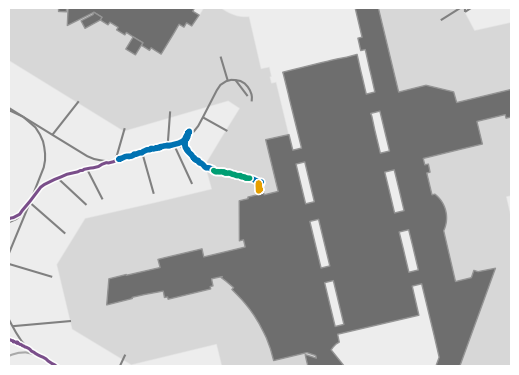

In [3]:
# Plot 1

fig, ax = create_pushback_comparison_plot(
    airport="KBOS",
    season="Summer",
    date="25-06-26",
    flight_id="ACA765",
    methods=("parking_area", "parking_position"),
    center_point=100,
    view_width_m=500,
    view_height_m=357,
    figsize=(5.0, 7.0),
)


navigationaid=beacon not in stylesheet, hence ignored


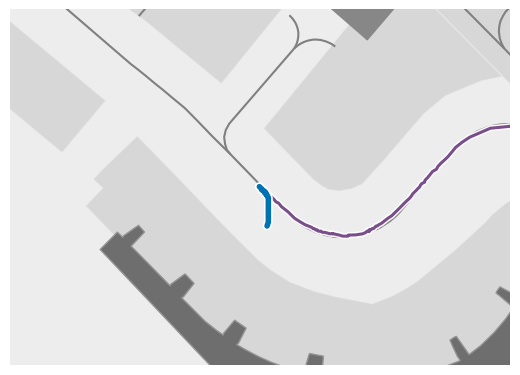

In [4]:
# Plot 2

fig, ax = create_pushback_comparison_plot(
    airport="KBOS",
    season="Summer",
    date="25-06-26",
    flight_id="DAL1399",
    methods=("parking_area",),
    first=600,
    center_point=100,
    view_width_m=500,
    view_height_m=357,
    figsize=(5.0, 7.0),
)


navigationaid=beacon not in stylesheet, hence ignored


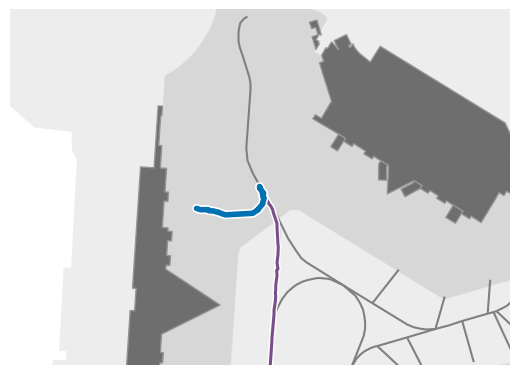

In [5]:
# Plot 3

fig, ax = create_pushback_comparison_plot(
    airport="KBOS",
    season="Summer",
    date="25-06-26",
    flight_id="DAL1245",
    methods=("parking_area", "parking_position"),
    first=600,
    center_point=100,
    view_width_m=500,
    view_height_m=357,
    figsize=(5.0, 7.0),
)

navigationaid=beacon not in stylesheet, hence ignored


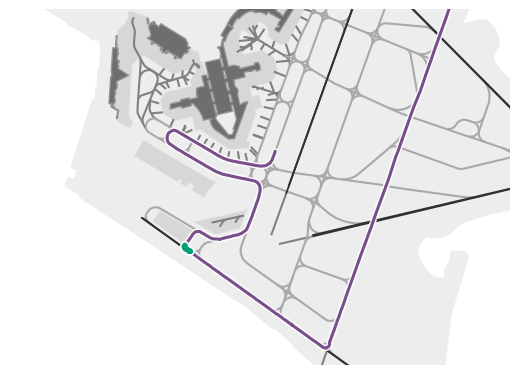

In [6]:
# Plot 4

fig, ax = create_pushback_comparison_plot(
    airport="KBOS",
    season="Autumn",
    date="18-10-25",
    flight_id="UAL366_956",
    methods=("parking_position","parking_position"),
    center_point=300,
    view_width_m=2500,
    view_height_m=1786,
    figsize=(5.0, 7.0),
)